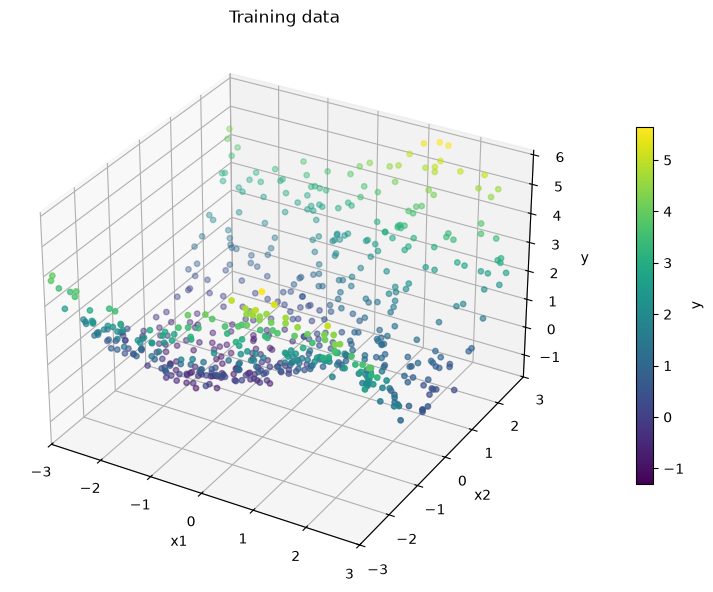

In [1]:
# 3A

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error

torch.set_num_threads(2)
torch.use_deterministic_algorithms(True)

folder = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
names = ["train.csv", "val.csv", "test.csv"]

if not all((folder / name).is_file() for name in names):
    if all((folder / "upload" / name).is_file() for name in names):
        folder = folder / "upload"
    else:
        from tkinter import Tk, filedialog

        root = Tk()
        root.withdraw()
        root.attributes("-topmost", True)
        selected = filedialog.askdirectory(
            parent=root,
            title="Select the folder containing train.csv, val.csv, and test.csv"
        )
        root.destroy()

        if not selected:
            raise FileNotFoundError("No data folder selected.")

        folder = Path(selected)

train = pd.read_csv(folder / "train.csv")
val = pd.read_csv(folder / "val.csv")
test = pd.read_csv(folder / "test.csv")

X_train = train[["x1", "x2"]].to_numpy(dtype=np.float64)
y_train = train["y"].to_numpy(dtype=np.float64)
X_val = val[["x1", "x2"]].to_numpy(dtype=np.float64)
y_val = val["y"].to_numpy(dtype=np.float64)
X_test = test[["x1", "x2"]].to_numpy(dtype=np.float64)

assert all(
    np.isfinite(a).all()
    for a in [X_train, y_train, X_val, y_val, X_test]
)

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection="3d")

points = ax.scatter(
    X_train[:, 0], X_train[:, 1], y_train,
    c=y_train, cmap="viridis", s=15
)

ax.set(
    xlabel="x1", ylabel="x2", zlabel="y",
    title="Training data", xlim=(-3, 3), ylim=(-3, 3)
)

fig.colorbar(points, ax=ax, shrink=0.65, label="y", pad=0.1)
plt.tight_layout()
plt.show()

   Sigma  Training MSE  Validation MSE
0.250000      0.010827        0.623048
0.500000      0.023366        0.063344
1.000000      0.028944        0.044172
2.000000      0.030514        0.037911
4.000000      0.032362        0.036664
Selected sigma: 4.0


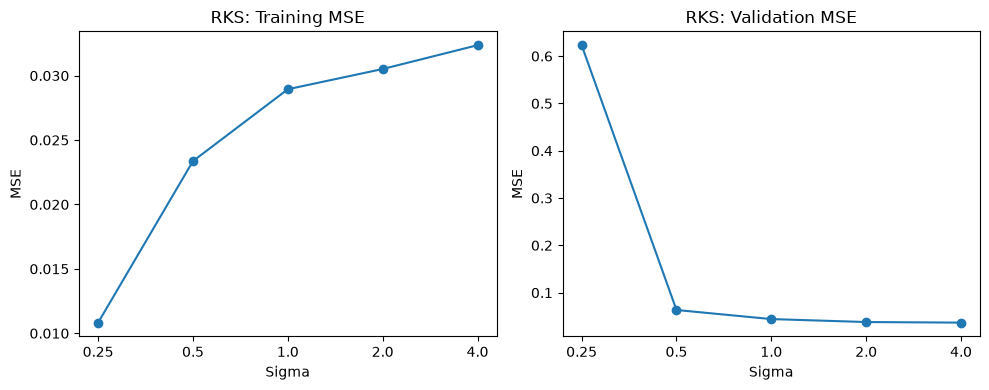

In [2]:
# 3B

class RKS:
    def __init__(self, sigma, D=1000, ridge_lambda=1e-3):
        rng = np.random.default_rng(42)
        self.W = rng.normal(size=(2, D // 2)) / sigma
        self.b = rng.uniform(0, 2 * np.pi, size=D // 2)
        self.regression = Ridge(
            alpha=ridge_lambda, solver="cholesky"
        )

    def features(self, X):
        angles = X @ self.W + self.b
        return np.stack(
            [np.sin(angles), np.cos(angles)], axis=2
        ).reshape(len(X), -1)

    def fit(self, X, y):
        self.regression.fit(self.features(X), y)
        return self

    def predict(self, X):
        return self.regression.predict(self.features(X))


sigma_values = [0.25, 0.5, 1.0, 2.0, 4.0]
rks_records = []

for sigma in sigma_values:
    model = RKS(sigma).fit(X_train, y_train)

    rks_records.append({
        "Sigma": sigma,
        "Training MSE": mean_squared_error(
            y_train, model.predict(X_train)
        ),
        "Validation MSE": mean_squared_error(
            y_val, model.predict(X_val)
        )
    })

rks_results = pd.DataFrame(rks_records)
best_sigma = float(
    rks_results.loc[
        rks_results["Validation MSE"].idxmin(), "Sigma"
    ]
)

print(rks_results.to_string(
    index=False, float_format=lambda v: f"{v:.6f}"
))
print("Selected sigma:", best_sigma)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, metric in zip(
    axes, ["Training MSE", "Validation MSE"]
):
    ax.plot(
        rks_results["Sigma"], rks_results[metric], marker="o"
    )
    ax.set(
        xlabel="Sigma", ylabel="MSE", title=f"RKS: {metric}"
    )
    ax.set_xscale("log", base=2)
    ax.set_xticks(
        sigma_values, labels=[str(v) for v in sigma_values]
    )

plt.tight_layout()
plt.show()

Finished hidden width 16
Finished hidden width 32
Finished hidden width 64
Finished hidden width 128
Finished hidden width 256
 Hidden units  Training MSE  Validation MSE
           16      0.035829        0.044757
           32      0.033402        0.043847
           64      0.031117        0.040412
          128      0.028422        0.038681
          256      0.026964        0.039586
Selected hidden width: 128


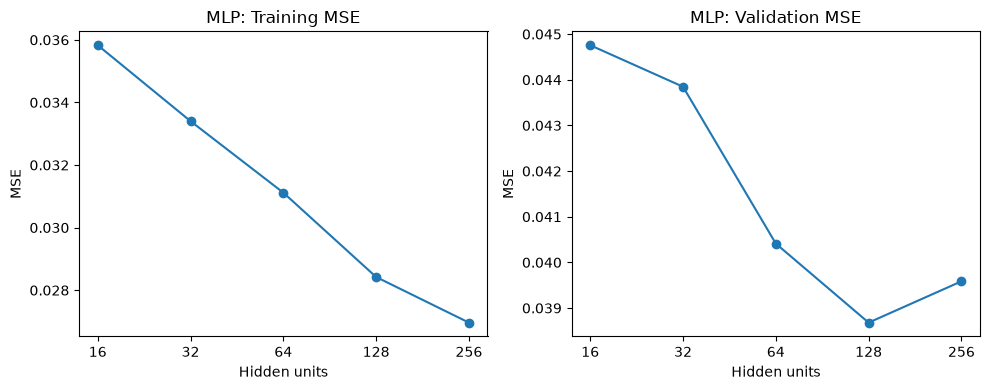

In [3]:
# 3C

class MLP(nn.Module):
    def __init__(self, width):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(2, width),
            nn.ReLU(),
            nn.Linear(width, 1)
        )

    def forward(self, x):
        return self.net(x).squeeze(1)

    @torch.no_grad()
    def predict(self, X):
        self.eval()
        inputs = torch.tensor(X, dtype=torch.float32)
        return self(inputs).numpy().astype(np.float64)


def fit_mlp(width):
    torch.manual_seed(42)
    model = MLP(width)

    optimizer = torch.optim.Adam(
        model.parameters(), lr=0.003, weight_decay=1e-5
    )

    inputs = torch.tensor(X_train, dtype=torch.float32)
    targets = torch.tensor(y_train, dtype=torch.float32)

    model.train()

    for epoch in range(3000):
        optimizer.zero_grad(set_to_none=True)
        loss = nn.functional.mse_loss(model(inputs), targets)
        loss.backward()
        optimizer.step()

    return model


width_values = [16, 32, 64, 128, 256]
mlp_records = []

for width in width_values:
    model = fit_mlp(width)

    mlp_records.append({
        "Hidden units": width,
        "Training MSE": mean_squared_error(
            y_train, model.predict(X_train)
        ),
        "Validation MSE": mean_squared_error(
            y_val, model.predict(X_val)
        )
    })

    print(f"Finished hidden width {width}")

mlp_results = pd.DataFrame(mlp_records)
best_width = int(
    mlp_results.loc[
        mlp_results["Validation MSE"].idxmin(), "Hidden units"
    ]
)

print(mlp_results.to_string(
    index=False, float_format=lambda v: f"{v:.6f}"
))
print("Selected hidden width:", best_width)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, metric in zip(
    axes, ["Training MSE", "Validation MSE"]
):
    ax.plot(
        mlp_results["Hidden units"],
        mlp_results[metric],
        marker="o"
    )
    ax.set(
        xlabel="Hidden units", ylabel="MSE",
        title=f"MLP: {metric}"
    )
    ax.set_xscale("log", base=2)
    ax.set_xticks(
        width_values, labels=[str(v) for v in width_values]
    )

plt.tight_layout()
plt.show()

Model  Validation MSE
  RKS        0.036664
  MLP        0.038681
Prediction files saved in: C:\Users\qingx\Desktop\AIML\hw2\q3


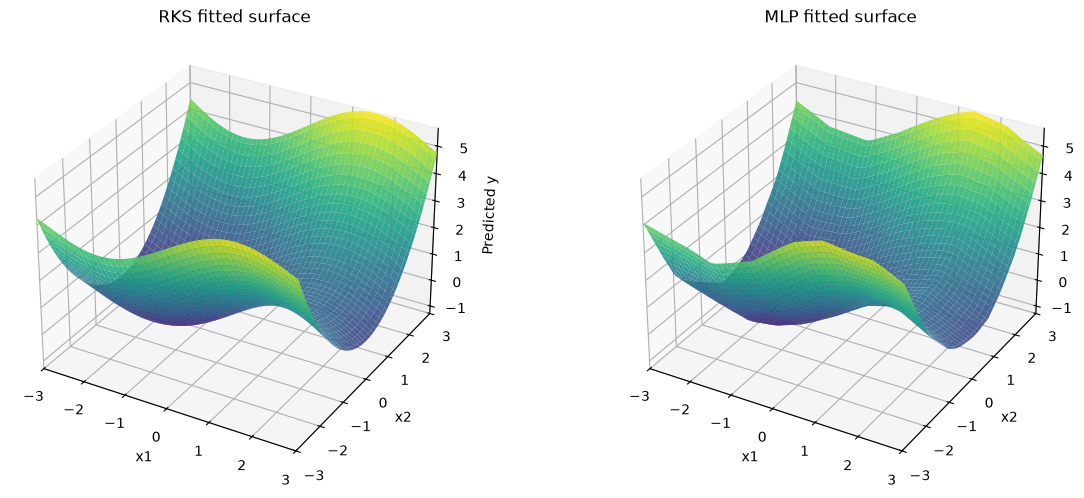

In [4]:
# 3D

rks_model = RKS(best_sigma).fit(X_train, y_train)
mlp_model = fit_mlp(best_width)

comparison = pd.DataFrame([
    {
        "Model": "RKS",
        "Validation MSE": mean_squared_error(
            y_val, rks_model.predict(X_val)
        )
    },
    {
        "Model": "MLP",
        "Validation MSE": mean_squared_error(
            y_val, mlp_model.predict(X_val)
        )
    }
])

print(comparison.to_string(
    index=False, float_format=lambda v: f"{v:.6f}"
))

rks_test = rks_model.predict(X_test)
mlp_test = mlp_model.predict(X_test)

assert len(rks_test) == len(mlp_test) == len(test)
assert np.isfinite(rks_test).all() and np.isfinite(mlp_test).all()

pd.DataFrame({"prediction": rks_test}).to_csv(
    folder / "rks_test_predictions.csv",
    index=False,
    header=False
)

pd.DataFrame({"prediction": mlp_test}).to_csv(
    folder / "mlp_test_predictions.csv",
    index=False,
    header=False
)

print("Prediction files saved in:", folder)

grid = np.linspace(-3, 3, 100)
x1, x2 = np.meshgrid(grid, grid)
grid_X = np.column_stack([x1.ravel(), x2.ravel()])

surfaces = [
    rks_model.predict(grid_X).reshape(x1.shape),
    mlp_model.predict(grid_X).reshape(x1.shape)
]

z_min = min(
    y_train.min(), *(surface.min() for surface in surfaces)
)
z_max = max(
    y_train.max(), *(surface.max() for surface in surfaces)
)

fig = plt.figure(figsize=(13, 5))

for i, (name, surface) in enumerate(
    zip(["RKS fitted surface", "MLP fitted surface"], surfaces),
    start=1
):
    ax = fig.add_subplot(1, 2, i, projection="3d")

    ax.plot_surface(
        x1, x2, surface,
        cmap="viridis",
        vmin=z_min,
        vmax=z_max,
        alpha=0.9
    )

    ax.set(
        xlabel="x1", ylabel="x2", zlabel="Predicted y",
        title=name,
        xlim=(-3, 3), ylim=(-3, 3), zlim=(z_min, z_max)
    )

plt.tight_layout()
plt.show()